In [1]:
# Task 1: Download the dataset and explore the video sequences
import os, random, warnings
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
warnings.filterwarnings('ignore')
random.seed(42)
np.random.seed(42)

seq_dirs = []
for d, _, files in os.walk('/kaggle/input'):
    b = os.path.basename(d).lower()
    if (b.startswith('fall') or b.startswith('adl')) and 'cam0' in b and any(f.endswith('.png') for f in files):
        seq_dirs.append(d)
seq_dirs = sorted(seq_dirs)
labels = np.array([1 if os.path.basename(d).lower().startswith('fall') else 0 for d in seq_dirs])
counts = [len([f for f in os.listdir(d) if f.endswith('.png')]) for d in seq_dirs]
print('Sequences:', len(seq_dirs), '| Falls:', int(labels.sum()), '| ADL:', int((labels == 0).sum()))
print('Frames per sequence: min', min(counts), 'max', max(counts))

Sequences: 70 | Falls: 30 | ADL: 40
Frames per sequence: min 55 max 400


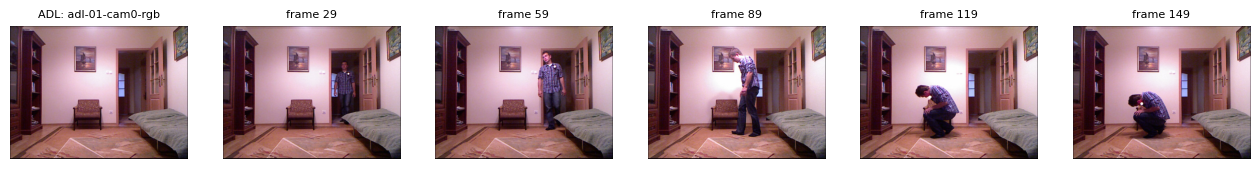

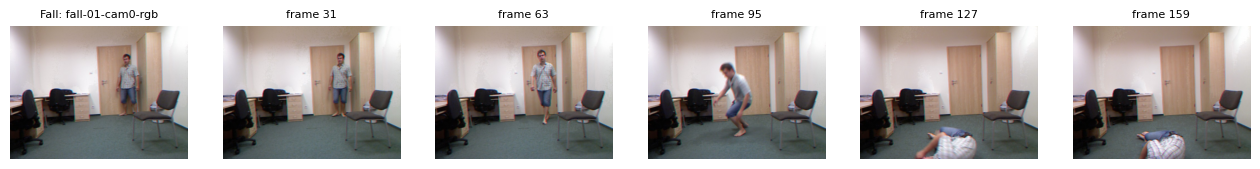

In [2]:
# Task 1: Differentiate normal activity and fall sequences visually
def show_sequence(d, title, n=6):
    files = sorted(f for f in os.listdir(d) if f.endswith('.png'))
    idx = np.linspace(0, len(files) - 1, n).astype(int)
    for k, i in enumerate(idx):
        ax = plt.subplot(1, n, k + 1)
        ax.imshow(Image.open(os.path.join(d, files[i])).convert('RGB'))
        ax.axis('off')
        ax.set_title(title if k == 0 else 'frame ' + str(i), fontsize=8)

plt.figure(figsize=(16, 3))
show_sequence(seq_dirs[int(np.where(labels == 0)[0][0])], 'ADL: ' + os.path.basename(seq_dirs[int(np.where(labels == 0)[0][0])]))
plt.show()
plt.figure(figsize=(16, 3))
show_sequence(seq_dirs[int(np.where(labels == 1)[0][0])], 'Fall: ' + os.path.basename(seq_dirs[int(np.where(labels == 1)[0][0])]))
plt.show()

In [3]:
# Task 2: Verify and remove corrupted video files
good = []
for i, d in enumerate(seq_dirs):
    files = sorted(f for f in os.listdir(d) if f.endswith('.png'))
    ok = len(files) >= 32
    for f in files:
        try:
            with Image.open(os.path.join(d, f)) as im:
                im.verify()
        except Exception:
            ok = False
            break
    if ok:
        good.append(i)
    else:
        print('Removed corrupted sequence:', os.path.basename(d))
seq_dirs = [seq_dirs[i] for i in good]
labels = labels[good]
print('Sequences kept:', len(seq_dirs), '| Falls:', int(labels.sum()), '| ADL:', int((labels == 0).sum()))

Sequences kept: 70 | Falls: 30 | ADL: 40


In [4]:
# Task 2: Extract a fixed number of frames from each video
NUM_FRAMES = 32
frame_paths = []
for d in seq_dirs:
    files = sorted(f for f in os.listdir(d) if f.endswith('.png'))
    idx = np.linspace(0, len(files) - 1, NUM_FRAMES).astype(int)
    frame_paths.append([os.path.join(d, files[i]) for i in idx])
print('Frames selected per sequence:', NUM_FRAMES)

Frames selected per sequence: 32


In [5]:
# Task 2: Resize each frame to 112 x 112 and convert to RGB
SIZE = 112
X_raw = np.zeros((len(frame_paths), NUM_FRAMES, SIZE, SIZE, 3), dtype=np.uint8)
for i, paths in enumerate(frame_paths):
    for t, p in enumerate(paths):
        X_raw[i, t] = np.array(Image.open(p).convert('RGB').resize((SIZE, SIZE)))
print('Raw array shape:', X_raw.shape)

Raw array shape: (70, 32, 112, 112, 3)


In [6]:
# Task 2: Normalize pixel intensity values to the range [0, 1]
X = X_raw.astype(np.float32) / 255.0
print('Min:', X.min(), '| Max:', X.max())

Min: 0.0 | Max: 1.0


In [7]:
# Task 2: Stack frames sequentially to form 3D video tensors (frames x height x width x channels)
y = labels.astype(np.float32)
print('Video tensor shape (videos, frames, height, width, channels):', X.shape)
print('Label shape:', y.shape)

Video tensor shape (videos, frames, height, width, channels): (70, 32, 112, 112, 3)
Label shape: (70,)


In [8]:
# Task 2: Split data into training (70%), validation (15%) and testing (15%)
from sklearn.model_selection import train_test_split
idx_all = np.arange(len(X))
idx_train, idx_temp = train_test_split(idx_all, test_size=0.30, stratify=y, random_state=42)
idx_val, idx_test = train_test_split(idx_temp, test_size=0.50, stratify=y[idx_temp], random_state=42)
for name, ids in [('Train', idx_train), ('Validation', idx_val), ('Test', idx_test)]:
    print(name, len(ids), '| Falls:', int(y[ids].sum()), '| ADL:', int((y[ids] == 0).sum()))

Train 49 | Falls: 21 | ADL: 28
Validation 10 | Falls: 4 | ADL: 6
Test 11 | Falls: 5 | ADL: 6


In [9]:
# Task 2: Apply data augmentation (random horizontal flip, random crop, temporal frame jittering)
CLIP = 16

def augment(clip32):
    start = np.random.randint(0, NUM_FRAMES - CLIP + 1)
    clip = clip32[start:start + CLIP]
    if np.random.rand() < 0.5:
        clip = clip[:, :, ::-1, :]
    padded = np.pad(clip, ((0, 0), (8, 8), (8, 8), (0, 0)), mode='reflect')
    dy, dx = np.random.randint(0, 17, size=2)
    clip = padded[:, dy:dy + SIZE, dx:dx + SIZE, :]
    return np.ascontiguousarray(clip)

def center_clip(clip32):
    start = (NUM_FRAMES - CLIP) // 2
    return clip32[start:start + CLIP]

sample = augment(X[idx_train[0]])
print('Augmented clip shape:', sample.shape)

Augmented clip shape: (16, 112, 112, 3)


In [10]:
# Task 2: Handle class imbalance with a weighted loss
n_pos = float(y[idx_train].sum())
n_neg = float(len(idx_train) - n_pos)
pos_weight_value = n_neg / n_pos
print('Fall clips:', int(n_pos), '| ADL clips:', int(n_neg), '| Positive class weight:', round(pos_weight_value, 3))

Fall clips: 21 | ADL clips: 28 | Positive class weight: 1.333


In [11]:
# Task 3: Prepare PyTorch datasets and data loaders
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)

class ClipDataset(Dataset):
    def __init__(self, ids, train):
        self.ids = ids
        self.train = train
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        j = self.ids[i]
        clip = augment(X[j]) if self.train else center_clip(X[j])
        clip = torch.from_numpy(np.ascontiguousarray(clip)).permute(3, 0, 1, 2).float()
        return clip, torch.tensor(y[j])

train_loader = DataLoader(ClipDataset(idx_train, True), batch_size=8, shuffle=True)
val_loader = DataLoader(ClipDataset(idx_val, False), batch_size=8)
test_loader = DataLoader(ClipDataset(idx_test, False), batch_size=8)
print('Device:', device)

Device: cuda


In [12]:
# Task 3: Implement the baseline 3D CNN for fall vs non-fall classification
def block(cin, cout, pool):
    return nn.Sequential(nn.Conv3d(cin, cout, 3, padding=1), nn.BatchNorm3d(cout), nn.ReLU(inplace=True), nn.MaxPool3d(pool))

class Fall3DCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            block(3, 16, (1, 2, 2)),
            block(16, 32, (2, 2, 2)),
            block(32, 64, (2, 2, 2)),
            block(64, 128, (2, 2, 2)),
            nn.AdaptiveAvgPool3d(1))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.5), nn.Linear(128, 1))
    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)

model = Fall3DCNN().to(device)
print('Parameters:', sum(p.numel() for p in model.parameters()))

Parameters: 292449


In [13]:
# Task 3: Train the model with validation and early stopping
import copy
criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight_value, device=device))
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

def run_epoch(loader, train):
    model.train(train)
    total, n = 0.0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            loss = criterion(model(xb), yb)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total += loss.item() * len(xb)
            n += len(xb)
    return total / n

best_loss, best_state, wait, patience = float('inf'), None, 0, 10
for epoch in range(1, 61):
    tr = run_epoch(train_loader, True)
    va = run_epoch(val_loader, False)
    print('Epoch', epoch, '| train loss', round(tr, 4), '| val loss', round(va, 4))
    if va < best_loss:
        best_loss, best_state, wait = va, copy.deepcopy(model.state_dict()), 0
    else:
        wait += 1
        if wait >= patience:
            print('Early stopping at epoch', epoch)
            break
model.load_state_dict(best_state)

Epoch 1 | train loss 0.9273 | val loss 0.895
Epoch 2 | train loss 0.4674 | val loss 0.6866
Epoch 3 | train loss 0.4102 | val loss 0.7186
Epoch 4 | train loss 0.476 | val loss 0.2861
Epoch 5 | train loss 0.509 | val loss 0.5157
Epoch 6 | train loss 0.2984 | val loss 1.4307
Epoch 7 | train loss 0.4422 | val loss 1.1289
Epoch 8 | train loss 0.3326 | val loss 0.3538
Epoch 9 | train loss 0.2571 | val loss 0.2246
Epoch 10 | train loss 0.2264 | val loss 1.8366
Epoch 11 | train loss 0.294 | val loss 0.233
Epoch 12 | train loss 0.185 | val loss 0.7226
Epoch 13 | train loss 0.309 | val loss 0.2458
Epoch 14 | train loss 0.1786 | val loss 0.0517
Epoch 15 | train loss 0.4941 | val loss 3.9338
Epoch 16 | train loss 0.258 | val loss 2.8069
Epoch 17 | train loss 0.2009 | val loss 0.0451
Epoch 18 | train loss 0.1569 | val loss 0.1563
Epoch 19 | train loss 0.1035 | val loss 0.0519
Epoch 20 | train loss 0.1687 | val loss 0.3776
Epoch 21 | train loss 0.1612 | val loss 0.9249
Epoch 22 | train loss 0.1089 |

<All keys matched successfully>

In [14]:
# Task 3: Evaluate with accuracy, precision, recall, F1-score and AUROC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve
model.eval()
probs, truth = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        probs.extend(torch.sigmoid(model(xb.to(device))).cpu().numpy().tolist())
        truth.extend(yb.numpy().tolist())
probs, truth = np.array(probs), np.array(truth).astype(int)
preds = (probs >= 0.5).astype(int)
print('Accuracy :', round(accuracy_score(truth, preds), 4))
print('Precision:', round(precision_score(truth, preds, zero_division=0), 4))
print('Recall   :', round(recall_score(truth, preds, zero_division=0), 4))
print('F1-score :', round(f1_score(truth, preds, zero_division=0), 4))
print('AUROC    :', round(roc_auc_score(truth, probs), 4))

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0
AUROC    : 1.0


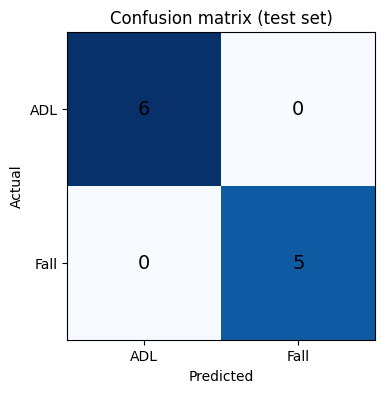

In [15]:
# Task 3: Analyze the confusion matrix
cm = confusion_matrix(truth, preds, labels=[0, 1])
plt.figure(figsize=(4, 4))
plt.imshow(cm, cmap='Blues')
plt.xticks([0, 1], ['ADL', 'Fall'])
plt.yticks([0, 1], ['ADL', 'Fall'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center', fontsize=14)
plt.title('Confusion matrix (test set)')
plt.show()

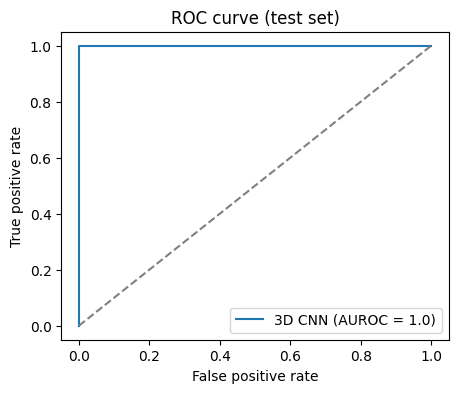

In [16]:
# Task 3: Analyze the ROC curve
fpr, tpr, _ = roc_curve(truth, probs)
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label='3D CNN (AUROC = ' + str(round(roc_auc_score(truth, probs), 3)) + ')')
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve (test set)')
plt.legend()
plt.show()

In [17]:
# Task 3: Identify common misclassifications and relate them to camera view, occlusion or motion blur
test_names = [os.path.basename(seq_dirs[j]) for j in idx_test]
wrong = [k for k in range(len(truth)) if preds[k] != truth[k]]
print('Misclassified test sequences:', len(wrong), 'of', len(truth))
if wrong:
    plt.figure(figsize=(4 * len(wrong), 3.4))
    for n, k in enumerate(wrong):
        ax = plt.subplot(1, len(wrong), n + 1)
        ax.imshow(X[idx_test[k]][NUM_FRAMES // 2])
        ax.axis('off')
        ax.set_title(test_names[k] + '\nactual ' + ('fall' if truth[k] else 'ADL') + ', fall prob ' + str(round(float(probs[k]), 2)), fontsize=8)
    plt.show()

Misclassified test sequences: 0 of 11
